## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Noah Weinstein

**Date:** 10/12/26


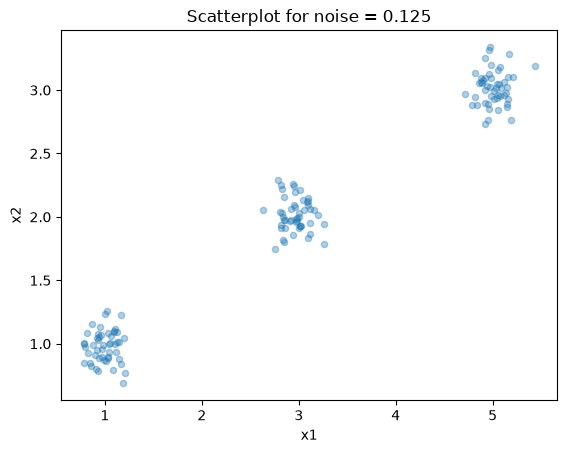

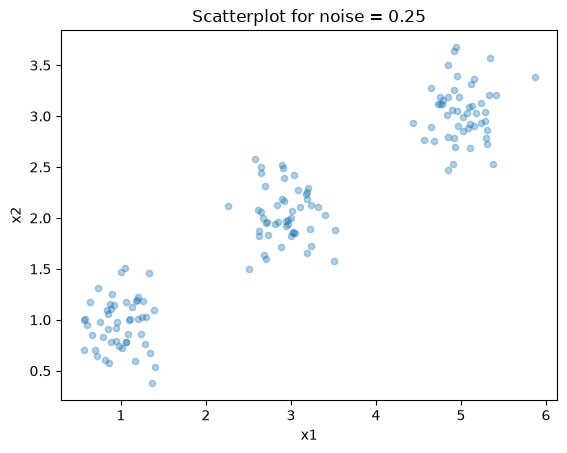

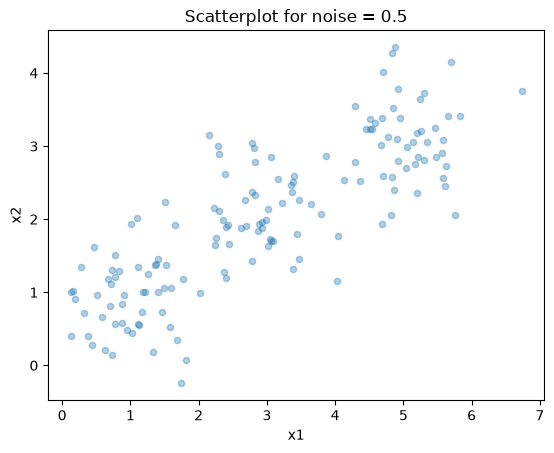

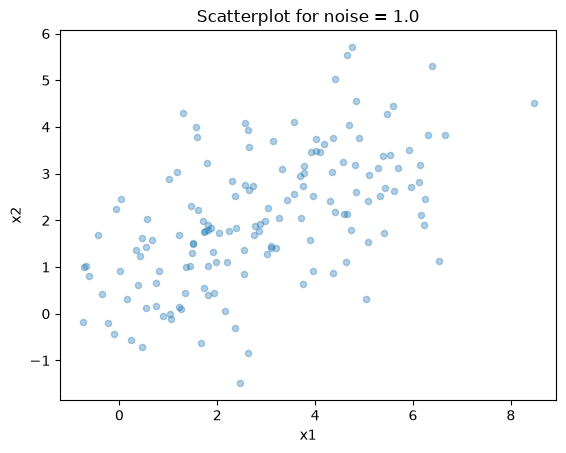

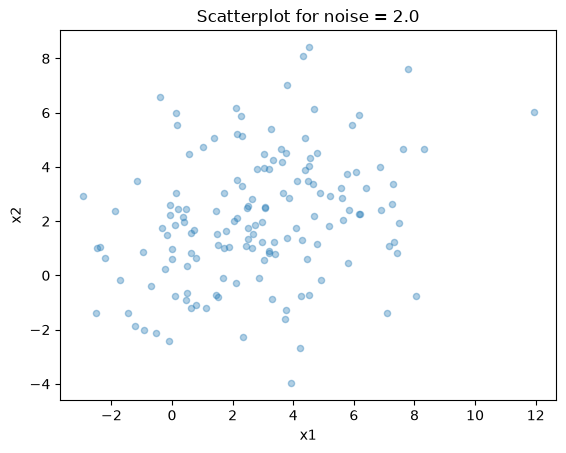

In [16]:
# Your Phase 1 solution to the problem goes here.
#Q1

import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

#Part 2
import matplotlib.pyplot as plt 

df0_125.plot.scatter(x = 0, y = 1, alpha = 0.35)
plt.title("Scatterplot for noise = 0.125")
plt.show()

df0_25.plot.scatter(x = 0, y = 1, alpha = 0.35)
plt.title("Scatterplot for noise = 0.25")
plt.show()

df0_5.plot.scatter(x = 0, y = 1, alpha = 0.35)
plt.title("Scatterplot for noise = 0.5")
plt.show()

df1_0.plot.scatter(x = 0, y = 1, alpha = 0.35)
plt.title("Scatterplot for noise = 1.0")
plt.show()

df2_0.plot.scatter(x = 0, y = 1, alpha = 0.35)
plt.title("Scatterplot for noise = 2.0")
plt.show()

#Visually, as noise increases, the spread of the points from their original clusters increases. 
#By spread = 0.5, you can't really differentiate between the clusters but can still see the line they
#originally fell on, but at 1.0 and 2.0 the data became much less patterned. 

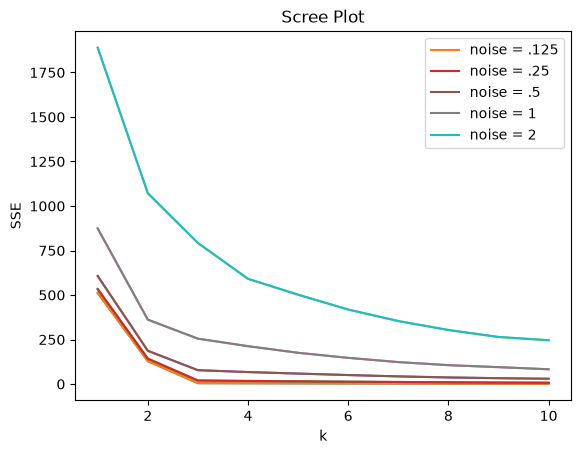

In [17]:
#Q1 Part 3 (new cell so I don't have to keep scrolling past the scatterplots)

import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.cluster import KMeans

datasets = {".125": df0_125, ".25": df0_25, ".5": df0_5, "1": df1_0, "2": df2_0}
ks = np.arange(1, 11)
ax = None

for name, dataset in datasets.items():
    SSE = [
        KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(dataset[["x1", "x2"]]).inertia_ for k in ks]
    sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")

    ax = sns.lineplot(x=ks, y=SSE, label=f"noise = {name}", ax=ax)


# I plotted them all together to not have to worry about scaling issues. The level of noise pretty clearly affects the rigidity of the 
# elbow of the scree plot, in a really intuitive manner. The noisier model is, the harder it is to find a harsh elbow and thus
# to difinitively find a value for k. 

# Adding onto that and touching on Q4, the elbow is the point on the Scree plot where the slope of SSE vs k drops the most. The slope
# is pretty much the rate of change of SSE with respect to k, so it's basically finding the point where increasing k further matters
# less and less to the change in SSE. In this situation, when the data isn't noisy and is pretty cleanly centered around its cluster
# points, it makes sense that we'd have a clear elbow at some value k, since the data clearly favors that number of groups. As the data
# gets up to higher noise levels and spreads out like we saw in the scatterplots, there are less clear clusters, and therefore k is less clear. 

(148, 7)


index                                                            \
         count         mean          std     min     25%     50%     75%   
cluster                                                                    
0         30.0  2782.600000  1664.320688   236.0  1494.0  2769.0  4307.5   
1          6.0  3783.333333   843.766476  2582.0  3194.0  4027.0  4375.5   
2        111.0  2768.540541  1665.488123    32.0  1205.0  2752.0  4112.0   
3          1.0  5540.000000          NaN  5540.0  5540.0  5540.0  5540.0   

                  Year          ... Percent of Government Spending            \
            max  count    mean  ...                            75%       max   
cluster                         ...                                            
0        5506.0   30.0  2020.0  ...                       0.048819  0.114776   
1        4656.0    6.0  2020.0  ...                       0.164503  0.225050   
2        5880.0  111.0  2020.0  ...                       0.083508  0.303027   
3        5540.0    1.0  2020.0  ...                       0.081976  0.081976   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                      30.0   607.478618  206.928757   362.467076   
1                       6.0  1706.721916  466.375705  1193.598730   
2                     111.0    80.061470   83.501824     0.580129   
3                       1.0  2351.631858         NaN  2351.631858   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0         422.208252   579.004604   757.328513  1070.623322  
1        1412.083201  1665.447478  1817.219993  2520.398541  
2          14.880549    47.056944   125.387558   314.201312  
3        2351.631858  2351.631858  2351.631858  2351.631858  

[4 rows x 48 columns]

,Country,cluster
5540,United States of America,3


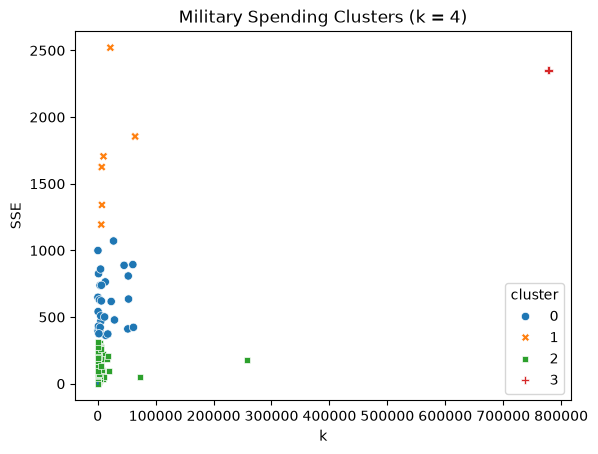

In [18]:
#Q2
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.cluster import KMeans

df_raw = pd.read_csv("data/SIPRI Military Expenditure Database.csv")

df = df_raw[df_raw["Year"] == 2020].dropna().copy()
print(df.shape)
# No, I don't think anything further is required. I also have 148 countries, and I think it's fine as is. The only thing I would flag
# is perhaps the fact that the index values aren't totally lined up, but it doesn't really matter for the scope of what we're doing.

features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])


ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")

#Seems like the elbow is at 4

model = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X)
df["cluster"] = model.labels_
ax = sns.scatterplot(
    data=df,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster",
    style="cluster",
    palette="tab10",
)
placeholder_variable = ax.set(title="Military Spending Clusters (k = 4)") # placeholder so it doesn't output random stuff

#Now, the describe table

display(df.groupby("cluster").describe())
#Find the US

df.loc[df["Country"].str.contains("United States"), ["Country", "cluster"]]



#I notice that the clusters are very uneven in size -- some have as low as 1 and 6, while the largest has 111. The spending per capita is also quite varied.
# The united states is in group 2, making it the sole one in that group. Interesting finding



(148, 7)


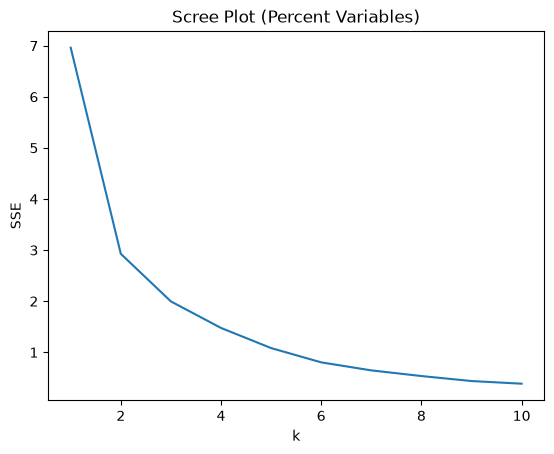

index                                                           \
             count         mean          std    min     25%     50%     75%   
cluster_pct                                                                   
0            113.0  2863.628319  1621.311342   32.0  1562.0  2888.0  4248.0   
1             35.0  2726.742857  1777.194225  100.0   899.0  2854.0  4061.0   

                      Year          ... Percent of Government Spending  \
                max  count    mean  ...                            75%   
cluster_pct                         ...                                  
0            5880.0  113.0  2020.0  ...                       0.051496   
1            5540.0   35.0  2020.0  ...                       0.143584   

                      Spending per Capita                                     \
                  max               count        mean         std        min   
cluster_pct                                                                    
0            0.101501               113.0  198.896006  267.036807   0.580129   
1            0.303027                35.0  492.225610  706.054294  18.297119   

                                                             
                   25%         50%         75%          max  
cluster_pct                                                  
0            14.945330   71.422125  303.716973  1341.058851  
1            49.954868  187.766671  624.127089  2520.398541  

[2 rows x 48 columns]

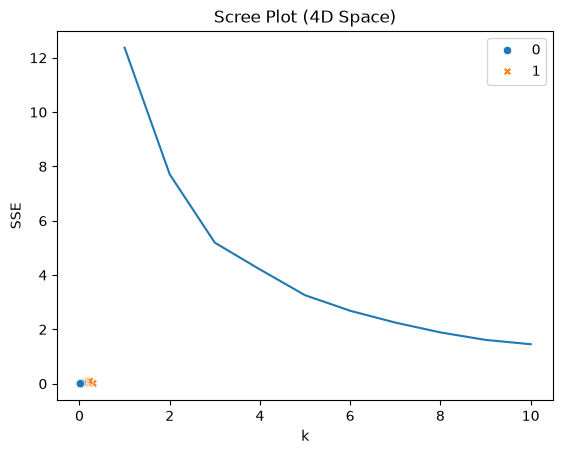

cluster_all
0    111
1     31
2      6
Name: count, dtype: int64

cluster_all                                       0             1  \
Spending (2020 USD)            count     111.000000     31.000000   
                               mean     7086.472777   8786.086602   
                               std     26479.379918  17901.909108   
                               min         8.622460    162.373364   
                               25%       130.010211    467.787851   
                               50%       567.650747   1404.787234   
                               75%      3910.107493   7739.166193   
                               max    257973.429834  72937.064048   
Spending per Capita            count     111.000000     31.000000   
                               mean      196.926833    212.689100   
                               std       267.788506    257.841988   
                               min         0.580129     18.297119   
                               25%        14.880549     46.485917   
                               50%        67.083417    135.459845   
                               75%       295.296094    217.333791   
                               max      1341.058851    998.966186   
Percent of Government Spending count     111.000000     31.000000   
                               mean        0.040350      0.122985   
                               std         0.019320      0.043927   
                               min         0.004896      0.076005   
                               25%         0.026712      0.093093   
                               50%         0.037952      0.114776   
                               75%         0.050505      0.134663   
                               max         0.092044      0.303027   
Percent of GDP                 count     111.000000     31.000000   
                               mean        0.013419      0.033492   
                               std         0.005996      0.011449   
                               min         0.000054      0.011742   
                               25%         0.008873      0.027560   
                               50%         0.013589      0.032024   
                               75%         0.017769      0.040531   
                               max         0.028132      0.066600   

cluster_all                                       2  
Spending (2020 USD)            count       6.000000  
                               mean   147964.582042  
                               std    309635.189564  
                               min      6095.708713  
                               25%      7700.424616  
                               50%     15897.570598  
                               75%     53872.942442  
                               max    778397.200000  
Spending per Capita            count       6.000000  
                               mean     1875.150751  
                               std       489.800206  
                               min      1193.598730  
                               25%      1645.301864  
                               50%      1780.059564  
                               75%      2227.318999  
                               max      2520.398541  
Percent of Government Spending count       6.000000  
                               mean        0.135351  
                               std         0.055392  
                               min         0.081976  
                               25%         0.101034  
                               50%         0.113271  
                               75%         0.164503  
                               max         0.225050  
Percent of GDP                 count       6.000000  
                               mean        0.062634  
                               std         0.028275  
                               min         0.029429  
                               25%         0.041272  
                               50%         0.059257  
                               75%         0.085

,Country,cluster_pct,cluster_all
5540,United States of America,1,2


In [ ]:
# Copy the above code with the percentage values for part 3
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

df_raw = pd.read_csv("data/SIPRI Military Expenditure Database.csv")

df = df_raw[df_raw["Year"] == 2020].dropna().copy()
print(df.shape)


features_pct = ["Percent of Government Spending", "Percent of GDP"]
unscaled_pct = df.loc[:, features_pct]
mins_pct = unscaled_pct.min()
ranges_pct = unscaled_pct.max() - mins_pct
X_pct = (unscaled_pct - mins_pct) / ranges_pct
X_pct.agg(["min", "max"])

# Scree plot
ks = np.arange(1, 11)
SSE_pct = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X_pct).inertia_
    for k in ks
]
_ = sns.lineplot(x=ks, y=SSE_pct).set(title="Scree Plot (Percent Variables)", xlabel="k", ylabel="SSE")
plt.show()
#scree plot shows an elbow at 2


k_pct = 2   
model_pct = KMeans(n_clusters=k_pct, n_init=10, random_state=0).fit(X_pct)
df["cluster_pct"] = model_pct.labels_

ax = sns.scatterplot(
    data=df,
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="cluster_pct",
    style="cluster_pct",
    palette="tab10",)

placeholder_variable = ax.set(title=f"Clusters on Percent Variables (k = {k_pct})")

#Now, the describe table

display(df.groupby("cluster_pct").describe())
#Find the US

df.loc[df["Country"].str.contains("United States"), ["Country", "cluster_pct"]]

#The US is in group 1, which makes sense -- they're heavier on government spending.

#And in terms of general output comparisons, this seems to make sense. There's a clearer split between a dense group (group 0) of low military spending as a
#share of budget and GDP, and a less dense group (1) where those shares are higher.There's no gap between the two, though, so I feel like the division is arbitrary.

#part 4
#Need new variables -- I just messed everything up for a second but fixed it

features_all = ["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP",]
unscaled_all = df.loc[:, features_all]
mins_all = unscaled_all.min()
ranges_all = unscaled_all.max() - mins_all
X_all = (unscaled_all - mins_all) / ranges_all
X_all.agg(["min", "max"])

ks = np.arange(1, 11)
SSE_all = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X_all).inertia_
    for k in ks
]
placeholder_variable_3 = sns.lineplot(x=ks, y=SSE_all).set(title="Scree Plot (4D Space)", xlabel="k", ylabel="SSE")
plt.show()

#k_all = 3

k_all = 3  
model_all = KMeans(n_clusters=k_all, n_init=10, random_state=0).fit(X_all)
df["cluster_all"] = model_all.labels_

display(df["cluster_all"].value_counts())
display(df.groupby("cluster_all")[features_all].describe().T)
display(df.loc[df["Country"].str.contains("United States"), ["Country", "cluster_pct", "cluster_all"]])


#Upon running a four-input (4 dimensional) kMC, we got k=3. There are no straggler (USA) solo-categories; our smallest here has 6 entries. Part 4 generally 
#combines our category-split insights from parts 2 and 3. 

#Honestly, I don't think so. It picked out the high-budget group, but the elbows were unconvincing and the distinctions between the groups weren't super inspiring.
#All in all, I'm less convinced with this method than I have been with previous weeks.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** ed0f39c
- **AI tool and model used:** Gemini Flash 3.6

### *Prompts used

1. The notebook I provided has a prompt for phase 1, then my code, then a prompt for phase 2. Phase 2 is AI revision. Give me specific feedback on how to improve my phase 1 code in regards to the prompt
2. Focus on the most important ones, and explain why they are so important.

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Color-Code the Scatterplots by Group (Q1.2): Update your plotting code to map the group assignments (a, b, c) to distinct colors (e.g., using sns.scatterplot(..., hue='group') or Matplotlib's c parameter). Plotting points in a single color prevents you from visually demonstrating how cluster separation breaks down as noise increases.
2. Implement $k$-Means Scree/Elbow Plots (Q1.3): Fit KMeans across a range of cluster counts (e.g., $k = 1$ to $8$) for each noise dataset and plot the resulting inertia (WCSS) versus $k$. Generating these curves is required to visually identify the "elbow" and answer the conceptual reflection in Part 4.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | This is a fair suggestion, I just didn't think of it honestly. |
| 2 | Reject | I don't exactly understand what it's talking about here. I looped through ks using code directly from the slideshow, so I'm trusting what we talked about in class over what the AI's thinking here.  |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

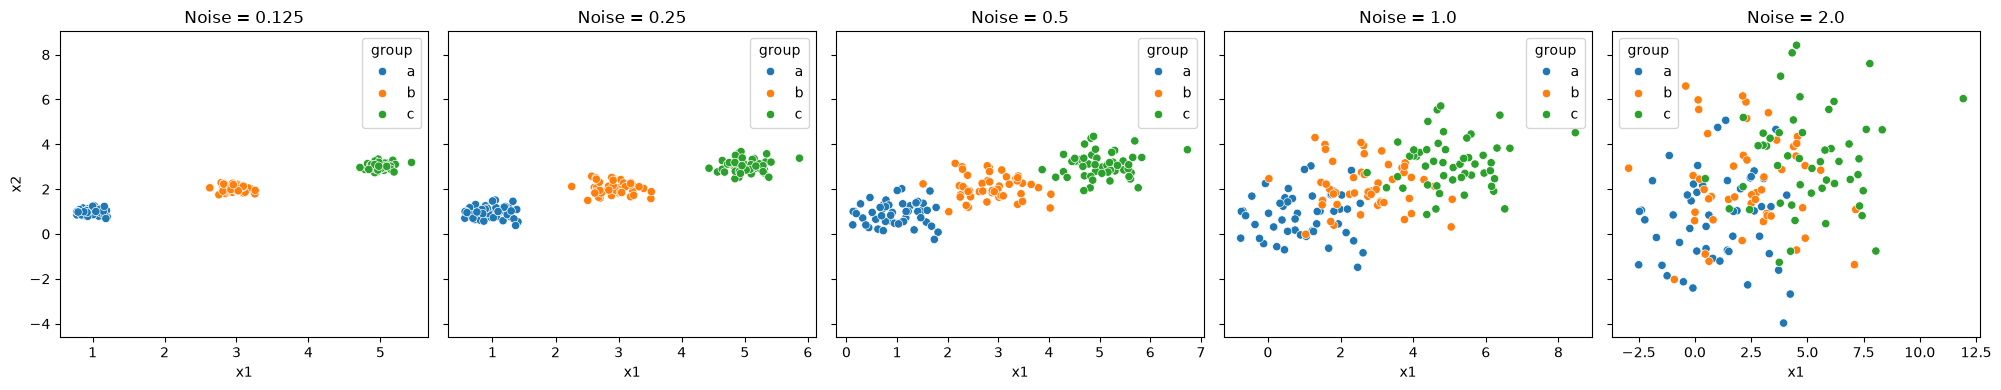

In [3]:
# Your Phase 2 solution to the problem goes here.

#Everything stays the same, except for Q1.2 -- will paste the new version below:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
datasets = {'0.125': df0_125, '0.25': df0_25, '0.5': df0_5, '1.0': df1_0,'2.0': df2_0}
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
for ax, (noise, df) in zip(axes, datasets.items()):
    sns.scatterplot(data=df, x='x1', y='x2', hue='group', ax=ax)
    ax.set_title(f'Noise = {noise}')
plt.tight_layout()
plt.show()

### *Reflection on AI assistance
In your own words without generative AI.

I found AI to be slightly underwhelming for this assignment again. In general, for other subjects, I find it excellent for revising my work, but I think it's slightly inefficient for proofreading these types of assignments, in large part because either the code works or it doesn't. It was helpful for me in making the noise comparison plots differentiated, but it didn't seem to understand what I was trying to do in its other suggestion. But in general, I think that AI is more useful for helping execute code ideas than helping verify already-implemented code issues. I don't push phase one until my code runs fully, so I don't think phase 2 makes a whole lot of conceptual sense, except for the weeks where I made a few mistakes. I'm looking forward to getting more exposure with AI assistance in code implementation for our project, which is our group's original idea, as opposed to reviewing our execution of pre-thought-up assignments.